# G1.11 · Distributed data parallel from scratch: naive → overlapped → bucketed, vs `torch` DDP

**ID:** G1.11 · **Target:** 110 min · **Plan week:** 15 · **Part:** G1

**The lab.** Guide G1: "write a 2-process DDP script with `torch.distributed`". You will write it four times,
each version fixing the previous one's bottleneck, and prove every version computes *exactly* what single-process
training on the concatenated batch computes:
1. **naive DDP**: broadcast the initial parameters, all-reduce (average) every gradient after `backward()`;
2. **flat**: one all-reduce on a flattened gradient buffer (fewer, larger messages);
3. **overlapped**: launch an async all-reduce per parameter from `register_post_accumulate_grad_hook`, so
   communication runs while autograd is still computing earlier layers' gradients;
4. **bucketed**: group gradients into ~25 MB buckets in reverse order, as PyTorch's DDP Reducer and picotron do;

then compare all of them with `torch.nn.parallel.DistributedDataParallel` for correctness and step time on this
PCIe box. You will open up DDP's Reducer (bucket layout, `bucket_cap_mb`, the 1 MiB first bucket, rebuilt
order, `find_unused_parameters`, comm hooks), and use `no_sync()` for gradient accumulation.

**Prerequisites:** G1.10 (collectives, the busbw you measured on this machine). Fill in the
`raise NotImplementedError` blocks inside the `%%writefile` cells, re-run that cell, then the launch cell.

## Sources
- S. Li, Y. Zhao, R. Varma, O. Salpekar, P. Noordhuis, T. Li, A. Paszke, J. Smith, B. Vaughan, P. Damania,
  S. Chintala, *PyTorch Distributed: Experiences on Accelerating Data Parallel Training*, VLDB 2020,
  arXiv:2006.15704, DOI 10.14778/3415478.3415530 — https://arxiv.org/abs/2006.15704 (bucketing, overlap, reverse
  bucket order, unused-parameter detection, `no_sync`).
- PyTorch DDP design note: https://docs.pytorch.org/docs/stable/notes/ddp.html · DDP API (`bucket_cap_mb`,
  `gradient_as_bucket_view`, `static_graph`, `find_unused_parameters`):
  https://docs.pytorch.org/docs/stable/generated/torch.nn.parallel.DistributedDataParallel.html · comm hooks:
  https://docs.pytorch.org/docs/stable/ddp_comm_hooks.html · `Tensor.register_post_accumulate_grad_hook`:
  https://docs.pytorch.org/docs/stable/generated/torch.Tensor.register_post_accumulate_grad_hook.html
- Stanford CS336 Spring 2026, Assignment 2 §5.2-5.3 (naive DDP, flat gradients, overlap with
  `register_post_accumulate_grad_hook`, `finish_gradient_synchronization()` interface) and `tests/test_ddp.py`
  (the equivalence test idea: same init, disjoint shards, compare with the full-batch model).
  stanford-cs336/assignment2-systems@ca8bc81, MIT. Interface and test idea adapted; code and prose ours.
- Hugging Face picotron, `picotron/data_parallel/bucket.py` and `data_parallel.py` (Bucket / BucketManager,
  `no_sync`), huggingface/picotron@59714b1, Apache-2.0. Our `DDPBucketed` adapts its bucket bookkeeping.
- S. Raschka, *Build a Large Language Model (From Scratch)*, appendix A, `DDP-script.py`
  (`DistributedSampler`, `mp.spawn`), rasbt/LLMs-from-scratch@f9313ea, Apache-2.0. Local copy:
  `../../LLMs-from-scratch/appendix-A/01_main-chapter-code/DDP-script.py` (the gentle introduction to read first).
- P. Goyal et al., *Accurate, Large Minibatch SGD: Training ImageNet in 1 Hour*, 2017, arXiv:1706.02677
  (linear learning-rate scaling with global batch size; BatchNorm statistics are per-worker).
- N. Tazi et al., *The Ultra-Scale Playbook*, Hugging Face 2025, §"Data Parallelism" (overlap, bucketing,
  gradient accumulation interplay): https://huggingface.co/spaces/nanotron/ultrascale-playbook

## 1. Why averaging gradients is exactly large-batch training
Global batch $\mathcal{B}$ of size $B$ split into $N$ disjoint shards $\mathcal{B}_r$ of size $B/N$. With the
mean loss $L = \frac1B\sum_{i\in\mathcal B}\ell_i$,
$$\nabla L = \frac1B\sum_{r}\sum_{i\in\mathcal B_r}\nabla\ell_i = \frac1N\sum_r \underbrace{\frac{N}{B}\sum_{i\in\mathcal B_r}\nabla\ell_i}_{\nabla L_r\ \text{(local mean-loss grad)}}.$$
So if every rank starts from the **same parameters** and applies the **same averaged gradient** with the same
optimizer, the replicas stay identical and the trajectory equals single-process training on $\mathcal B$.
Fine print that interviewers like:
- It needs *equal shard sizes* (otherwise weight the average) and the same loss reduction.
- **BatchNorm** computes statistics per rank (use `SyncBatchNorm` if that matters). **Dropout** masks differ per
  rank, which is fine (and intended) but breaks bitwise comparisons.
- Global batch $B$ grows with $N$, so the LR usually needs retuning (Goyal et al. 2017: linear scaling + warmup).
- The float sum is computed in a different order than the single-process reduction: expect ~1e-7 relative
  differences, so compare with `allclose`.

```
  rank 0: [model θ] -- fwd/bwd on shard 0 --> g0 ─┐
  rank 1: [model θ] -- fwd/bwd on shard 1 --> g1 ─┼── all-reduce(mean) ──> ḡ on every rank ──> θ ← opt(θ, ḡ)
  rank 2: [model θ] -- fwd/bwd on shard 2 --> g2 ─┘
```
Read Raschka's `DDP-script.py` (path in Sources) for the standard user-facing version: `DistributedSampler`
shards the dataset by rank, `DDP(model, device_ids=[rank])` wraps the model, and the training loop is unchanged.
Below you build the wrapper yourself.

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from prep import Session, check, check_close

s = Session("G1.11", target_min=110)
NGPU = torch.cuda.device_count()
NPROC = min(4, NGPU) if NGPU >= 2 else 2
BACKEND = "nccl" if NGPU >= 2 else "gloo"
RUN = Path("runs_G1.11")
RUN.mkdir(exist_ok=True)
print(f"{NGPU} GPUs -> NPROC={NPROC}, backend={BACKEND}")


def torchrun(script, *args, nproc=NPROC, timeout=900):
    """Run `torchrun --standalone --nproc_per_node={nproc} script args` inside RUN/; raise if any rank fails."""
    args = [str(a) for a in args]
    print(f"$ torchrun --standalone --nproc_per_node={nproc} {script} {' '.join(args)}")
    env = {**os.environ, "BACKEND": BACKEND, "OMP_NUM_THREADS": "2"}
    cmd = [sys.executable, "-m", "torch.distributed.run", "--standalone", f"--nproc_per_node={nproc}", script, *args]
    p = subprocess.run(cmd, cwd=RUN, capture_output=True, text=True, timeout=timeout, env=env)
    print(p.stdout)
    if p.returncode != 0:
        print(p.stderr[-6000:])
        raise RuntimeError(f"{script} exited with code {p.returncode}")


def load(name):
    return json.loads((RUN / name).read_text())

[G1.11] started 16:51; target 110 min
4 GPUs -> NPROC=4, backend=nccl


In [2]:
%%writefile runs_G1.11/dist_utils.py
import json
import os
import time

import torch
import torch.distributed as dist


def setup():
    """Init the default process group from torchrun's env vars and bind this process to its GPU."""
    backend = os.environ.get("BACKEND", "nccl" if torch.cuda.device_count() >= 2 else "gloo")
    local_rank = int(os.environ["LOCAL_RANK"])
    if backend == "nccl":
        dev = torch.device("cuda", local_rank)
        torch.cuda.set_device(dev)
        dist.init_process_group("nccl", device_id=dev)
    else:
        dev = torch.device("cpu")
        dist.init_process_group("gloo")
    torch.backends.cuda.matmul.allow_tf32 = False   # exact fp32 so equivalence checks can be tight
    torch.backends.cudnn.allow_tf32 = False
    return dist.get_rank(), dist.get_world_size(), dev


def sync(dev):
    if dev.type == "cuda":
        torch.cuda.synchronize(dev)


def bench(fn, dev, warmup=3, iters=8):
    """Median seconds per fn() call; the slowest rank's median is returned on every rank."""
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(iters):
        dist.barrier()
        sync(dev)
        t0 = time.perf_counter()
        fn()
        sync(dev)
        times.append(time.perf_counter() - t0)
    t = torch.tensor([sorted(times)[len(times) // 2]], device=dev)
    dist.all_reduce(t, op=dist.ReduceOp.MAX)
    return float(t.item())


def max_over_ranks(x, dev):
    t = torch.tensor([float(x)], device=dev)
    dist.all_reduce(t, op=dist.ReduceOp.MAX)
    return float(t.item())


def save(name, obj):
    if dist.get_rank() == 0:
        with open(name, "w") as f:
            json.dump(obj, f, indent=1)

Overwriting runs_G1.11/dist_utils.py


## 2. Your DDP implementations (one module, four strategies)
Fill in every block. The harness scripts below import this file.

**Naive.** `broadcast_params` copies rank 0's parameters (and buffers) to everyone, so different random inits
don't matter. `allreduce_grads` runs after `loss.backward()`: one blocking `all_reduce` per gradient, then
divide by $N$.

**Flat.** Same result with a single all-reduce on `torch._utils._flatten_dense_tensors(grads)`, then copy
the unflattened views back (CS336 §5.3.1). That is one latency $\alpha$ instead of ~100, but nothing starts
until backward has finished.

**Overlap.** Autograd finishes the last layer's gradients first. `p.register_post_accumulate_grad_hook(fn)`
calls `fn(p)` right after `p.grad` is fully accumulated for this backward. Launch
`dist.all_reduce(p.grad, async_op=True)` there and keep the work handle. `finish_gradient_synchronization()`
waits on all handles before `optimizer.step()`. With NCCL, `wait()` makes the compute stream wait for the
communication stream; it does not block the CPU. Divide by $N$ *before* the all-reduce (torch's default
`allreduce_hook` does the same, which also avoids fp16 overflow).

**Bucketed.** Many small all-reduces each pay $\alpha$. Group parameters into buckets of at most
`bucket_cap_mb` MiB, **in reverse registration order** (≈ the order gradients become ready, so the first bucket
fills first). A single parameter bigger than the cap gets a bucket of its own. Each bucket owns a flat buffer:
the hook copies `p.grad` into its slice and, when the bucket's last gradient arrives, launches one async
all-reduce on the whole buffer. `finish` waits and copies the averaged slices back into `p.grad`. If a bucket
never launched, some parameter received no gradient. Raise a clear error; that is what
`find_unused_parameters` exists for.

In [3]:
%%writefile runs_G1.11/my_ddp.py
import torch
import torch.distributed as dist
import torch.nn as nn


def broadcast_params(model, src=0):
    """Make every rank's parameters and buffers equal to rank `src`'s (in place)."""
    with torch.no_grad():
        for t in list(model.parameters()) + list(model.buffers()):
            dist.broadcast(t, src=src)


def allreduce_grads(model):
    """Blocking: replace every p.grad by its mean over ranks, one all_reduce per tensor."""
    n = dist.get_world_size()
    for p in model.parameters():
        if p.grad is not None:
            dist.all_reduce(p.grad, op=dist.ReduceOp.SUM)
            p.grad.div_(n)


def allreduce_grads_flat(model):
    """Blocking: same result with ONE all_reduce on a flattened copy of all grads."""
    grads = [p.grad for p in model.parameters() if p.grad is not None]
    flat = torch._utils._flatten_dense_tensors(grads)
    dist.all_reduce(flat)
    flat.div_(dist.get_world_size())
    for g, f in zip(grads, torch._utils._unflatten_dense_tensors(flat, grads)):
        g.copy_(f)


class DDPOverlap(nn.Module):
    """Per-parameter async all-reduce launched from post-accumulate-grad hooks."""

    def __init__(self, module):
        super().__init__()
        self.module = module
        self.world = dist.get_world_size()
        self.handles = []
        broadcast_params(module)
        for p in module.parameters():
            if p.requires_grad:
                p.register_post_accumulate_grad_hook(self._hook)

    def _hook(self, p):
        p.grad.div_(self.world)
        self.handles.append(dist.all_reduce(p.grad, async_op=True))

    def forward(self, *args, **kwargs):
        return self.module(*args, **kwargs)

    def finish_gradient_synchronization(self):
        for h in self.handles:
            h.wait()
        self.handles.clear()


class DDPBucketed(nn.Module):
    """Reverse-order buckets of <= bucket_cap_mb MiB; one async all-reduce per bucket once it is full."""

    def __init__(self, module, bucket_cap_mb=25.0):
        super().__init__()
        self.module = module
        self.world = dist.get_world_size()
        broadcast_params(module)
        params = [p for p in module.parameters() if p.requires_grad]
        cap = int(bucket_cap_mb * 2**20)
        # self.buckets: list of lists of params; self.loc[p] = (bucket index, offset in bucket, numel)
        self.buckets, self.loc = [], {}
        cur, size = [], 0
        for p in reversed(params):
            nbytes = p.numel() * p.element_size()
            if cur and size + nbytes > cap:
                self.buckets.append(cur)
                cur, size = [], 0
            cur.append(p)
            size += nbytes
        if cur:
            self.buckets.append(cur)
        for b, ps in enumerate(self.buckets):
            off = 0
            for p in ps:
                self.loc[p] = (b, off, p.numel())
                off += p.numel()
        self.flat = [torch.zeros(sum(p.numel() for p in ps), device=ps[0].device, dtype=ps[0].dtype)
                     for ps in self.buckets]
        self._reset()
        for p in params:
            p.register_post_accumulate_grad_hook(self._hook)

    def _reset(self):
        self.pending = [len(ps) for ps in self.buckets]   # grads still missing per bucket
        self.handles = [None] * len(self.buckets)

    def _hook(self, p):
        b, off, n = self.loc[p]
        self.flat[b][off:off + n].copy_(p.grad.flatten())
        self.pending[b] -= 1
        if self.pending[b] == 0:
            self.flat[b].div_(self.world)
            self.handles[b] = dist.all_reduce(self.flat[b], async_op=True)

    def forward(self, *args, **kwargs):
        return self.module(*args, **kwargs)

    def finish_gradient_synchronization(self):
        for b, ps in enumerate(self.buckets):
            if self.handles[b] is None:
                raise RuntimeError(f"bucket {b} was never launched: a parameter received no gradient "
                                   "(this is the situation find_unused_parameters=True handles)")
            self.handles[b].wait()
            for p in ps:
                _, off, n = self.loc[p]
                p.grad.copy_(self.flat[b][off:off + n].view_as(p.grad))
        self._reset()

Overwriting runs_G1.11/my_ddp.py


## 3. Prove equivalence with single-process training
The harness, adapted from the idea of CS336's `test_ddp.py`:
- every rank builds the model with seed = rank, so replicas start **different**, and broadcast must fix that;
- each step draws a global batch from a shared seed, and rank $r$ trains on rows $[rB, (r+1)B)$;
- a reference model (seed 0 = rank 0's init) trains on the **whole** global batch in one process;
- after 5 SGD-with-momentum steps, every strategy's parameters must match the reference, and all replicas must
  be identical to each other.

It also runs one deliberately wrong variant (sum instead of mean) under SGD and under AdamW. Look at how
small the AdamW error is. Adam's update $m/(\sqrt v+\epsilon)$ is invariant to rescaling the gradient (up to
$\epsilon$), so **a missing $1/N$ is invisible with Adam**. Test DDP code with SGD.

In [4]:
%%writefile runs_G1.11/check_ddp.py
import copy

import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP

from dist_utils import max_over_ranks, save, setup
from my_ddp import DDPBucketed, DDPOverlap, allreduce_grads, allreduce_grads_flat, broadcast_params
from prep.tinygpt import GPT, GPTConfig

rank, N, dev = setup()
cfg = GPTConfig(vocab_size=256, context_length=32, d_model=64, n_heads=4, n_layers=2)
B, STEPS = 4, 5                                     # per-rank batch, steps


def make(seed):
    torch.manual_seed(seed)
    return GPT(cfg).to(dev)


def global_batch(step):                             # same on every rank
    g = torch.Generator().manual_seed(1000 + step)
    x = torch.randint(0, cfg.vocab_size, (N * B, cfg.context_length + 1), generator=g).to(dev)
    return x[:, :-1], x[:, 1:]


def sgd(m):
    return torch.optim.SGD(m.parameters(), lr=0.05, momentum=0.9)


def adamw(m):
    return torch.optim.AdamW(m.parameters(), lr=1e-2)


def train_reference(make_opt):
    m = make(0)
    opt = make_opt(m)
    for step in range(STEPS):
        x, y = global_batch(step)
        opt.zero_grad()
        m(x, y)[1].backward()
        opt.step()
    return m


def train(strategy, make_opt):
    m = make(rank)                                   # deliberately different init per rank
    if strategy == "torch":
        model = DDP(m, device_ids=[dev.index] if dev.type == "cuda" else None)
        params_module = model.module
    elif strategy == "overlap":
        model = DDPOverlap(m)
        params_module = m
    elif strategy == "bucketed":
        model = DDPBucketed(m, bucket_cap_mb=0.05)  # tiny cap -> many buckets even for this small model
        params_module = m
    else:
        broadcast_params(m)
        model = params_module = m
    opt = make_opt(params_module)
    for step in range(STEPS):
        x, y = global_batch(step)
        x, y = x[rank * B:(rank + 1) * B], y[rank * B:(rank + 1) * B]
        opt.zero_grad()
        model(x, y)[1].backward()
        if strategy == "naive":
            allreduce_grads(m)
        elif strategy == "flat":
            allreduce_grads_flat(m)
        elif strategy == "sum_only":                 # the classic bug: forgot to divide by N
            for p in m.parameters():
                dist.all_reduce(p.grad)
        elif strategy in ("overlap", "bucketed"):
            model.finish_gradient_synchronization()
        opt.step()
    return params_module, model


def compare(m, ref):
    err = max((p - q).abs().max().item() for p, q in zip(m.parameters(), ref.parameters()))
    flat = torch.cat([p.detach().flatten() for p in m.parameters()])
    flat0 = flat.clone()
    dist.broadcast(flat0, src=0)                     # replicas must agree with rank 0
    return max_over_ranks(err, dev), max_over_ranks((flat - flat0).abs().max().item(), dev)


ref_sgd, ref_adam = train_reference(sgd), train_reference(adamw)
res = {"N": N}
init_diff = max((p - q).abs().max().item() for p, q in zip(make(rank).parameters(), make(0).parameters()))
res["init_differs_on_nonzero_ranks"] = max_over_ranks(init_diff, dev)
for strat in ("naive", "flat", "overlap", "bucketed", "torch"):
    m, model = train(strat, sgd)
    res[strat] = compare(m, ref_sgd)
    if strat == "bucketed":
        names = {id(p): n for n, p in m.named_parameters()}
        res["bucket_layout"] = [[names[id(p)] for p in ps] for ps in model.buckets]
        res["param_order"] = [n for n, p in m.named_parameters() if p.requires_grad]
        res["bucket_bytes"] = [sum(p.numel() * p.element_size() for p in ps) for ps in model.buckets]
res["sum_only_sgd"] = compare(train("sum_only", sgd)[0], ref_sgd)
res["sum_only_adamw"] = compare(train("sum_only", adamw)[0], ref_adam)
res["naive_adamw"] = compare(train("naive", adamw)[0], ref_adam)
if rank == 0:
    for k, v in res.items():
        if k not in ("bucket_layout", "param_order", "bucket_bytes"):
            print(f"{k:32s} {v}")
save("check_ddp.json", res)
dist.destroy_process_group()

Overwriting runs_G1.11/check_ddp.py


In [5]:
torchrun("check_ddp.py")
r = load("check_ddp.json")
check("ranks start from different random inits (so broadcast matters)", r["init_differs_on_nonzero_ranks"] > 1e-3)
for strat in ("naive", "flat", "overlap", "bucketed", "torch"):
    err_ref, err_replica = r[strat]
    check(f"{strat}: matches single-process full-batch training", err_ref < 2e-5, f"max |diff| = {err_ref:.2e}")
    check(f"{strat}: all replicas identical", err_replica < 1e-6, f"max |diff| = {err_replica:.2e}")
# AdamW divides by sqrt(v): near-zero gradients get O(lr) updates whose sign depends on 1e-7-level noise, so its
# tolerance must be looser than SGD's.
check("naive DDP with AdamW also matches (looser tolerance)", r["naive_adamw"][0] < 1e-3, str(r["naive_adamw"]))
check("missing 1/N is caught by SGD", r["sum_only_sgd"][0] > 1e-3, str(r["sum_only_sgd"]))
print(f"missing 1/N under AdamW: max |diff| = {r['sum_only_adamw'][0]:.1e} -- the same order as AdamW's own "
      f"round-off noise ({r['naive_adamw'][0]:.1e}); under SGD it is {r['sum_only_sgd'][0]:.1e} vs {r['naive'][0]:.1e}")

layout, order = r["bucket_layout"], r["param_order"]
check("buckets cover every parameter exactly once, in reverse registration order",
      [n for b in layout for n in b] == order[::-1])
cap = int(0.05 * 2**20)
check("bucket sizes respect the cap (single oversized params excepted)",
      all(nb <= cap or len(b) == 1 for nb, b in zip(r["bucket_bytes"], layout)))
print(f"{len(layout)} buckets; first bucket = {layout[0]}")

$ torchrun --standalone --nproc_per_node=4 check_ddp.py 


N                                4
init_differs_on_nonzero_ranks    0.13006384670734406
naive                            (7.450580596923828e-09, 0.0)
flat                             (7.450580596923828e-09, 0.0)
overlap                          (7.450580596923828e-09, 0.0)
bucketed                         (9.313225746154785e-09, 0.0)
torch                            (7.450580596923828e-09, 0.0)
sum_only_sgd                     (0.06902743875980377, 0.0)
sum_only_adamw                   (0.0032050181180238724, 0.0)
naive_adamw                      (2.0597130060195923e-05, 0.0)

ok  ranks start from different random inits (so broadcast matters)
ok  naive: matches single-process full-batch training
ok  naive: all replicas identical
ok  flat: matches single-process full-batch training
ok  flat: all replicas identical
ok  overlap: matches single-process full-batch training
ok  overlap: all replicas identical
ok  bucketed: matches single-process full-batch training
ok  bucketed: all replicas

## 4. What each strategy costs on this box
Workload: a 29.5M-parameter tinygpt (8 layers, $d=512$, vocab 8192; 118 MB of fp32 gradients), 16 sequences ×
256 tokens per rank, fp32, plain SGD. The harness times one full step (forward, backward, sync, optimizer step)
for each strategy. It also times two reference points: `local` (no communication at all, a lower bound) and
`comm_only` (one all-reduce of the 118 MB flat gradient buffer, nothing else). An ideally overlapped
implementation costs about $\max(t_\text{local}, t_\text{comm}) + $ the tail it cannot hide. A non-overlapped
one costs about $t_\text{local} + t_\text{comm}$.

In [6]:
%%writefile runs_G1.11/bench_ddp.py
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP

from dist_utils import bench, save, setup
from my_ddp import DDPBucketed, DDPOverlap, allreduce_grads, allreduce_grads_flat, broadcast_params
from prep.tinygpt import GPT, GPTConfig, num_params

rank, N, dev = setup()
cfg = GPTConfig(vocab_size=8192, context_length=256, d_model=512, n_heads=8, n_layers=8)
B = 16
torch.manual_seed(0)
base = GPT(cfg).to(dev)
g = torch.Generator().manual_seed(rank)
x_all = torch.randint(0, cfg.vocab_size, (B, cfg.context_length + 1), generator=g).to(dev)
x, y = x_all[:, :-1], x_all[:, 1:]
res = {"N": N, "params": num_params(base), "grad_MB": 4 * num_params(base) / 1e6, "t": {}}


def make(strategy):
    m = GPT(cfg).to(dev)
    m.load_state_dict(base.state_dict())
    if strategy in ("torch_ddp", "torch_ddp_view"):
        model = DDP(m, device_ids=[dev.index] if dev.type == "cuda" else None,
                    gradient_as_bucket_view=strategy.endswith("view"))
    elif strategy == "overlap":
        model = DDPOverlap(m)
    elif strategy == "bucketed_25MB":
        model = DDPBucketed(m, 25)
    else:
        broadcast_params(m)
        model = m
    opt = torch.optim.SGD(m.parameters(), lr=1e-4)

    def step():
        opt.zero_grad(set_to_none=False)
        model(x, y)[1].backward()
        if strategy == "naive":
            allreduce_grads(m)
        elif strategy == "flat":
            allreduce_grads_flat(m)
        elif strategy in ("overlap", "bucketed_25MB"):
            model.finish_gradient_synchronization()
        opt.step()
    return step


flat = torch.zeros(num_params(base), device=dev)
res["t"]["comm_only"] = bench(lambda: dist.all_reduce(flat), dev)
for strat in ("local", "naive", "flat", "overlap", "bucketed_25MB", "torch_ddp", "torch_ddp_view"):
    res["t"][strat] = bench(make(strat), dev)
    if rank == 0:
        print(f"{strat:16s} {res['t'][strat]*1e3:8.1f} ms/step")
save("bench_ddp.json", res)
dist.destroy_process_group()

Overwriting runs_G1.11/bench_ddp.py


$ torchrun --standalone --nproc_per_node=4 bench_ddp.py 


local                51.5 ms/step
naive                99.7 ms/step
flat                101.7 ms/step
overlap              84.9 ms/step
bucketed_25MB        95.4 ms/step
torch_ddp            91.2 ms/step
torch_ddp_view       90.9 ms/step

N=4, 29.5M params, 118 MB fp32 grads; comm_only = 45.0 ms, local = 51.5 ms


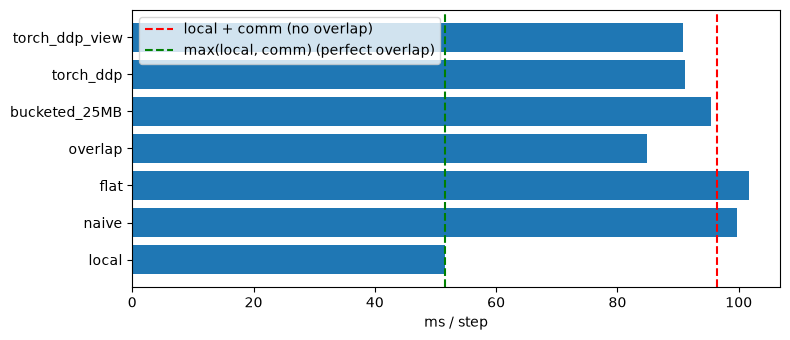

naive               99.7 ms   scaling efficiency vs no-comm step: 51.7%
flat               101.7 ms   scaling efficiency vs no-comm step: 50.7%
overlap             84.9 ms   scaling efficiency vs no-comm step: 60.7%
bucketed_25MB       95.4 ms   scaling efficiency vs no-comm step: 54.0%
torch_ddp           91.2 ms   scaling efficiency vs no-comm step: 56.5%
torch_ddp_view      90.9 ms   scaling efficiency vs no-comm step: 56.7%
ok  bucketed overlap beats naive per-tensor blocking all-reduce
ok  torch DDP beats naive per-tensor blocking all-reduce
ok  every DDP step is slower than the no-comm step (communication is real)


In [7]:
torchrun("bench_ddp.py")
b = load("bench_ddp.json")
t = b["t"]
print(f"N={b['N']}, {b['params']/1e6:.1f}M params, {b['grad_MB']:.0f} MB fp32 grads; "
      f"comm_only = {t['comm_only']*1e3:.1f} ms, local = {t['local']*1e3:.1f} ms")
names = ["local", "naive", "flat", "overlap", "bucketed_25MB", "torch_ddp", "torch_ddp_view"]
plt.figure(figsize=(8, 3.5))
plt.barh(names, [t[n] * 1e3 for n in names])
plt.axvline(t["local"] * 1e3 + t["comm_only"] * 1e3, color="r", ls="--", label="local + comm (no overlap)")
plt.axvline(max(t["local"], t["comm_only"]) * 1e3, color="g", ls="--", label="max(local, comm) (perfect overlap)")
plt.xlabel("ms / step")
plt.legend()
plt.tight_layout()
plt.show()
for n in names[1:]:
    eff = t["local"] / t[n]
    print(f"{n:16s} {t[n]*1e3:7.1f} ms   scaling efficiency vs no-comm step: {eff:5.1%}")
check("bucketed overlap beats naive per-tensor blocking all-reduce", t["bucketed_25MB"] < t["naive"])
check("torch DDP beats naive per-tensor blocking all-reduce", t["torch_ddp"] < t["naive"])
check("every DDP step is slower than the no-comm step (communication is real)",
      min(t[n] for n in names[1:]) > t["local"])

**Reading the numbers.** On this box the all-reduce of 118 MB costs a large fraction of the whole local step
(more with 4 ranks than with 2). That is the G1.10 lesson: with ~3 GB/s of busbw, communication is not a rounding
error. Expect:
- `naive` ≈ `local` + `comm_only` + per-call overhead (84 latency-bound calls);
- `flat` removes the per-call overhead but still overlaps nothing, and pays an extra copy;
- `overlap` and `bucketed_25MB` hide part of the communication under backward. They can never beat
  $\max(t_\text{local}, t_\text{comm})$, and the **tail** is the part that cannot overlap: the gradients of the
  first layers (and the embeddings) are ready only at the very end of backward;
- torch DDP ≈ your bucketed version (its Reducer is C++, uses the same reverse-order buckets, and
  `gradient_as_bucket_view=True` makes `p.grad` a view into the bucket, removing a copy and 1× gradient memory).

On an 8×H100 NVSwitch node the same all-reduce would take ~0.6 ms ($2\cdot\frac78\cdot 118$ MB / 370 GB/s), so DDP
overhead would round to zero. Same code, different regime.

## 5. Inside `torch` DDP: buckets, rebuilt order, unused parameters, `no_sync`
The Reducer (Li et al. 2020 §3-4; DDP design note):
- **Construction:** broadcasts rank 0's `state_dict` (parameters and buffers), assigns parameters to buckets in
  roughly **reverse** `model.parameters()` order with `bucket_cap_mb` (default 25 MiB) and a small first bucket
  (`dist._DEFAULT_FIRST_BUCKET_BYTES` = 1 MiB). The first bucket fills first, so a small one starts
  communication sooner. It also registers one autograd hook per parameter.
- **Backward:** when every gradient of a bucket is ready, it launches an async all-reduce of the bucket.
  Buckets are reduced **in index order** on every rank, so all ranks issue identical collective sequences.
  After the first iteration the Reducer **rebuilds** buckets in the order gradients actually arrived (the script
  prints `n_buckets_iter1`: the layout before the rebuild differs from the final one, so inspect iteration 2).
- **End of backward:** it waits for all buckets and writes averaged gradients into `p.grad` (or `p.grad` already
  *is* a view into the bucket with `gradient_as_bucket_view=True`).
- **Unused parameters:** a parameter that gets no gradient this iteration never marks its bucket ready, so the
  reduction never finishes. DDP raises at the next forward unless `find_unused_parameters=True`. That flag makes
  DDP traverse the autograd graph after every forward to mark unused parameters ready, which costs time.
  `static_graph=True` lets DDP learn the pattern once.
- **Comm hooks** replace the all-reduce per bucket. Examples: `fp16_compress_hook`, PowerSGD. Below we register a
  hook that records each bucket and then calls the default `allreduce_hook`.

**Gradient accumulation with `no_sync()`.** Accumulating $K$ microbatches per optimizer step needs the averaged
gradient only once. Inside `with model.no_sync():` the Reducer skips communication and the grads accumulate
locally. The backward *outside* the context syncs the accumulated sum. That is a $K\times$ reduction in
all-reduce traffic at equal tokens per step, and it is the first thing to try when DDP is communication-bound.

In [8]:
%%writefile runs_G1.11/torch_ddp.py
import torch
import torch.distributed as dist
import torch.nn as nn
from torch.distributed.algorithms.ddp_comm_hooks import default_hooks
from torch.nn.parallel import DistributedDataParallel as DDP

from dist_utils import max_over_ranks, save, setup
from prep.tinygpt import GPT, GPTConfig

rank, N, dev = setup()
ids = [dev.index] if dev.type == "cuda" else None
cfg = GPTConfig(vocab_size=8192, context_length=64, d_model=512, n_heads=8, n_layers=8)
res = {"N": N}


def recording_hook(state, bucket):
    """DDP comm hook: log (bucket index, MB, params) then do the default mean all-reduce."""
    state["calls"].append((bucket.index(), bucket.buffer().numel() * 4 / 2**20,
                           [state["names"][id(p)] for p in bucket.parameters()]))
    return default_hooks.allreduce_hook(None, bucket)


# (a) bucket layout as the Reducer actually uses it (iteration 2, after the rebuild)
torch.manual_seed(0)
model = DDP(GPT(cfg).to(dev), device_ids=ids)
state = {"calls": [], "names": {id(p): n for n, p in model.module.named_parameters()}}
model.register_comm_hook(state, recording_hook)
g = torch.Generator().manual_seed(rank)
xy = torch.randint(0, cfg.vocab_size, (4, cfg.context_length + 1), generator=g).to(dev)
for it in range(2):
    state["calls"].clear()
    model(xy[:, :-1], xy[:, 1:])[1].backward()
    if it == 0:
        res["n_buckets_iter1"] = len(state["calls"])
res["buckets"] = [(i, round(mb, 2), len(ps), ps[0], ps[-1]) for i, mb, ps in state["calls"]]

# (b) no_sync: K microbatches, communication only on the last; grads must equal the full-batch reference
K, b = 4, 2
torch.manual_seed(0)
ref = GPT(cfg).to(dev)
torch.manual_seed(0)                                    # same init as ref (DDP then broadcasts rank 0's anyway)
model = DDP(GPT(cfg).to(dev), device_ids=ids)
state = {"calls": [], "names": {id(p): n for n, p in model.module.named_parameters()}}
model.register_comm_hook(state, recording_hook)
model(xy[:, :-1], xy[:, 1:])[1].backward()             # one synced warm-up step so the Reducer rebuilds buckets
model.zero_grad(set_to_none=True)
state["calls"].clear()
gb = torch.Generator().manual_seed(7)
data = torch.randint(0, cfg.vocab_size, (N * K * b, cfg.context_length + 1), generator=gb).to(dev)
ref(data[:, :-1], data[:, 1:])[1].backward()          # one process, whole global batch
mine = data.view(N, K * b, -1)[rank]                   # this rank's K*b rows (disjoint across ranks)
for k in range(K):
    mb = mine[k * b:(k + 1) * b]
    if k < K - 1:
        with model.no_sync():
            (model(mb[:, :-1], mb[:, 1:])[1] / K).backward()
    else:
        (model(mb[:, :-1], mb[:, 1:])[1] / K).backward()
res["no_sync_grad_err"] = max_over_ranks(max((p.grad - q.grad).abs().max().item()
                                             for p, q in zip(model.module.parameters(), ref.parameters())), dev)
res["no_sync_bucket_calls"] = len(state["calls"])
res["n_buckets"] = len(res["buckets"])

# (c) an unused parameter without find_unused_parameters
class TwoHeads(nn.Module):
    def __init__(self):
        super().__init__()
        self.used, self.unused = nn.Linear(8, 8), nn.Linear(8, 8)

    def forward(self, x):
        return self.used(x)


for flag in (False, True):
    torch.manual_seed(0)
    m = DDP(TwoHeads().to(dev), device_ids=ids, find_unused_parameters=flag)
    try:
        for _ in range(2):
            m(torch.randn(4, 8, device=dev)).sum().backward()
        res[f"find_unused={flag}"] = "ok"
    except RuntimeError as e:
        res[f"find_unused={flag}"] = "RuntimeError: " + str(e).split("\n")[0][:160]
if rank == 0:
    print("bucket | MiB | #params | first param | last param")
    for row in res["buckets"]:
        print(row)
    for k in ("n_buckets_iter1", "no_sync_grad_err", "no_sync_bucket_calls", "n_buckets", "find_unused=False",
              "find_unused=True"):
        print(f"{k}: {res[k]}")
save("torch_ddp.json", res)
dist.destroy_process_group()

Overwriting runs_G1.11/torch_ddp.py


In [9]:
torchrun("torch_ddp.py")
d = load("torch_ddp.json")
check("no_sync accumulation equals full-batch gradient", d["no_sync_grad_err"] < 2e-5, str(d["no_sync_grad_err"]))
check("no_sync: only the last microbatch communicates (one call per bucket)",
      d["no_sync_bucket_calls"] == d["n_buckets"], f"{d['no_sync_bucket_calls']} calls for {d['n_buckets']} buckets")
check("first bucket holds the LAST layers (reverse order)", "blocks.7" in d["buckets"][0][3] or "ln_f" in d["buckets"][0][3]
      or "head" in d["buckets"][0][3], str(d["buckets"][0]))
check("unused parameter without find_unused_parameters raises", d["find_unused=False"].startswith("RuntimeError"))
check("find_unused_parameters=True handles it", d["find_unused=True"] == "ok")

$ torchrun --standalone --nproc_per_node=4 torch_ddp.py 


bucket | MiB | #params | first param | last param
(0, 4.01, 4, 'ln_f.weight', 'blocks.7.mlp.2.weight')
(1, 28.04, 22, 'blocks.7.mlp.0.bias', 'blocks.5.mlp.0.weight')
(2, 25.04, 23, 'blocks.5.ln2.weight', 'blocks.3.attn.proj.weight')
(3, 27.04, 21, 'blocks.3.attn.qkv.weight', 'blocks.1.attn.qkv.weight')
(4, 28.15, 14, 'blocks.1.ln1.weight', 'tok_emb.weight')
n_buckets_iter1: 1
no_sync_grad_err: 3.306195139884949e-08
no_sync_bucket_calls: 5
n_buckets: 5
find_unused=False: RuntimeError: Expected to have finished reduction in the prior iteration before starting a new one. This error indicates that your module has parameters that were not used in
find_unused=True: ok

ok  no_sync accumulation equals full-batch gradient
ok  no_sync: only the last microbatch communicates (one call per bucket)
ok  first bucket holds the LAST layers (reverse order)
ok  unused parameter without find_unused_parameters raises
ok  find_unused_parameters=True handles it


## Say it out loud
1. Prove that averaging per-rank mean-loss gradients equals the full-batch gradient. When does it stop being
   exact (unequal shards, BatchNorm, sum vs mean loss)?
2. Why must parameters be broadcast at the start, and why do the replicas stay in sync afterwards without ever
   communicating parameters?
3. Your DDP test passes with AdamW even though you forgot to divide by $N$. Why? How should DDP code be tested?
4. How does DDP overlap communication with backward? What determines the part that cannot overlap?
5. Why bucket? Why in reverse order? Why is DDP's first bucket only 1 MiB? What does `gradient_as_bucket_view` save?
6. Your job hangs or errors at the second iteration after you added an auxiliary head that is only used every
   other step. What is happening and what are the fixes?
7. How does `no_sync()` interact with gradient accumulation, and how much communication does it save?
8. DDP scaling efficiency is 60% on 8 GPUs. What do you measure first, and what knobs do you have?
9. DDP vs `nn.DataParallel`: why is the latter slower even on one machine?

<details><summary>Model answers</summary>

1. $\nabla\frac1B\sum_i\ell_i = \frac1N\sum_r\nabla\frac{N}{B}\sum_{i\in\mathcal B_r}\ell_i$ when every shard has
   $B/N$ items. Not exact if shards differ in size (or in token count after masking: weight by counts), if the
   loss is a sum (then don't divide), or if the model has cross-example coupling in the forward: BatchNorm uses
   per-rank statistics (SyncBatchNorm fixes it), and in-batch contrastive negatives are per-rank unless gathered.
   Float summation order also differs, so results agree to ~1e-7 relative, not bitwise.
2. Different seeds/devices give different inits. After a broadcast, the update $\theta \leftarrow
   \text{opt}(\theta, \bar g)$ is a deterministic function of identical inputs on every rank, so replicas stay
   identical by induction (as long as optimizer states also start identical and nothing rank-dependent sneaks in).
   DDP also broadcasts buffers each forward by default (`broadcast_buffers`).
3. Adam's update $m/(\sqrt{v}+\epsilon)$ is invariant to scaling the gradient by a constant (it cancels except
   through $\epsilon$), so a factor $N$ barely moves the parameters. Test with plain SGD and compare against
   single-process large-batch training, check replicas against each other, and check the gradient norm.
4. Hooks fire as each parameter's gradient becomes final, starting with the last layer. An async all-reduce
   launched there runs on NCCL's stream while autograd continues on the compute stream. `wait()` before the
   optimizer makes the compute stream wait. What can't be hidden: the all-reduce of the last-ready buckets
   (first layers, embeddings), launched after the final gradient, plus anything exceeding backward time when
   $t_\text{comm} > t_\text{backward}$ (this box).
5. Each collective pays a latency $\alpha$ (tens of µs here, G1.10), so ~100 tiny all-reduces waste time; one
   giant all-reduce can't start until backward ends. Buckets trade the two. Reverse order ≈ gradient-ready order,
   so the first bucket completes first. A small (1 MiB) first bucket starts communication as early as possible.
   `gradient_as_bucket_view=True` makes `p.grad` alias the bucket buffer: no copy in or out, and one fewer full
   copy of the gradients in memory.
6. In the steps where the head is unused its parameters get no gradient, its bucket never becomes ready, and
   DDP errors at the next forward ("Expected to have finished reduction in the prior iteration...") or ranks
   hang if they disagree. Fixes: `find_unused_parameters=True` (graph traversal each step, slower);
   `static_graph=True` if the pattern is fixed; or make the head always participate (e.g. multiply its output
   by 0 and add it to the loss, so it gets a zero gradient).
7. Inside `no_sync()` the hooks only accumulate into `.grad`; the backward outside the context communicates the
   accumulated sum (divide the loss by $K$ so it is a mean). Traffic drops by $K\times$ at the same global batch,
   at the price of $K$ sequential microbatches (more latency per step, same tokens).
8. First measure the no-communication step time and the communication time alone (as in §4), plus a profiler
   trace to see whether all-reduce overlaps backward. Then check: per-GPU batch too small (compute too short to
   hide comm), grad dtype (fp32 grads mean 2× bytes vs bf16 reduction), bucket size, the interconnect (PCIe vs
   NVLink, NIC count, `NCCL_DEBUG=INFO` transport), stragglers (data loading, uneven batches,
   one slow GPU, since DDP runs at the speed of the slowest rank), `find_unused_parameters` overhead. Knobs:
   larger per-GPU batch or `no_sync` accumulation, bf16 gradient comm hooks / PowerSGD, bigger buckets,
   gradient-as-bucket-view, overlap-friendly ordering, or switch strategy (FSDP/ZeRO to fit larger
   per-GPU batches, or hierarchical / low-communication methods across slow links).
9. `DataParallel` is single-process multi-threaded: the GIL serializes Python. It scatters inputs and
   replicates the model from GPU 0 every forward, gathers outputs to GPU 0 (imbalanced memory), and reduces
   gradients to GPU 0 instead of a ring all-reduce. DDP is one process per GPU, broadcasts once and
   all-reduces in overlapped buckets (Li et al. 2020).
</details>

In [10]:
s.finish(lookups=0, score=None, notes="")

[G1.11] done in 0.6 min (within target 110 min)


0.6153794606526692